# Notebook B (Shared Drive Edition) — Train from Shared Google Drive

This notebook is specifically configured to run on a **secondary Google Account (Colab)** using data prepared in **Account A's Google Drive**.

### ⚡ 2-Minute Setup for Shared Drive:
1. **Account A (Original Owner):** In Google Drive, ensure `hybrid_pgm_data` is shared with Account B as **Editor** (not Viewer, so checkpoints can be saved).
2. **Account B (Training Colab):** In Google Drive, go to **'Shared with me'** → Right-click `hybrid_pgm_data` → Select **'Organize'** (or three dots) → **'Add shortcut'** → Select **'My Drive'** → Click **'Add'**.
3. Run **Section 0** below. The notebook will automatically detect the shared folder shortcut, test write permissions, and start training!

---
**Pipeline Contents:**
1. Patient-level train / val / test splits with zero data leakage.
2. Fast embedding models: Linear probe, MLP, kNN, and Age/Sex/View confound baseline with clustered CIs.
3. Systematic Hyperparameter Tuning & Grid Search across 11 architectures.
4. Bayesian Network calibration and reliability diagrams.
5. Out-of-Core Incremental DenseNet-121 fine-tuning (`FT_BATCH = 4`, activation checkpointing, <= 10 GB disk).


In [ ]:
!pip install -q pgmpy scikit-learn scipy

## 0. Configuration

In [ ]:
import os, time, math, json, warnings, shutil
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
warnings.filterwarnings("ignore")

# ------------------------- MOUNT GOOGLE DRIVE -------------------------
from google.colab import drive
drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print(f"Device: {device} | Mixed Precision (AMP): {use_amp}")


Mounted at /content/drive
Device: cuda | Mixed Precision (AMP): True


In [ ]:
# ==============================================================================
# AUTOMATIC SHARED DRIVE PATH DETECTION & PERMISSION VERIFICATION
# ==============================================================================
def resolve_shared_drive_folder():
    candidate_paths = [
        "/content/drive/MyDrive/hybrid_pgm_data",
        "/content/drive/MyDrive/hybrid_pgm_data - Shortcut",
        "/content/drive/Shareddrives/hybrid_pgm_data",
        "/content/drive/MyDrive/Shared with me/hybrid_pgm_data"
    ]

    # 1. Quick check for direct paths or shortcuts
    for p in candidate_paths:
        if os.path.exists(p) and os.path.exists(os.path.join(p, "manifest.json")):
            return p

    # 2. Search MyDrive shallowly with symlink/shortcut resolution
    print("Searching for shared 'hybrid_pgm_data' shortcut in /content/drive/MyDrive...")
    try:
        for root, dirs, files in os.walk("/content/drive/MyDrive", followlinks=True):
            if "manifest.json" in files:
                if "hybrid_pgm" in root.lower() or "data" in root.lower():
                    return root
    except Exception as e:
        print(f"Search notice: {e}")

    return None

detected_work = resolve_shared_drive_folder()

if detected_work:
    WORK = detected_work
    print("=" * 75)
    print("✓ SUCCESS: Found project directory at:")
    print(f"  --> {WORK}")
    print("=" * 75)

    # Verify Write Permissions (Crucial for Account B!)
    test_file = os.path.join(WORK, ".test_write_perm.tmp")
    try:
        with open(test_file, "w") as f:
            f.write("ok")
        os.remove(test_file)
        print("✓ Google Drive Write Permission: GRANTED (Editor Access Verified)")
    except Exception as e:
        print("⚠️ WARNING: READ-ONLY ACCESS DETECTED!")
        print("  Account A shared this folder as 'Viewer' instead of 'Editor'.")
        print("  Please ask Account A to change your permission on 'hybrid_pgm_data' to 'Editor'")
        print("  so that checkpoints and result files can be saved to Drive.")
else:
    print("=" * 75)
    print("❌ FOLDER NOT FOUND IN ACCOUNT B's GOOGLE DRIVE!")
    print("=" * 75)
    print("Because this folder is shared from another account, Google Drive requires")
    print("one quick 5-second action to make it visible to Google Colab:")
    print("1. Open Google Drive on this account (drive.google.com)")
    print("2. Click 'Shared with me' on the left sidebar")
    print("3. Right-click on 'hybrid_pgm_data'")
    print("4. Click 'Organize' (or three dots) -> 'Add shortcut'")
    print("5. Select 'My Drive' and click 'Add'")
    print("Once added, re-run this cell and it will detect it instantly!")
    print("=" * 75)
    raise FileNotFoundError("hybrid_pgm_data folder shortcut not yet added to Account B's My Drive.")

# Configuration Parameters
SIZES        = [5000, 10000, 20000, 40000]
HEAD_SEEDS   = [0, 1, 2]
N_BOOT       = 1000
N_BOOT_SCALE = 200


✓ SUCCESS: Found project directory at:
  --> /content/drive/MyDrive/hybrid_pgm_data
✓ Google Drive Write Permission: GRANTED (Editor Access Verified)


## 1. Load the numbers from Drive and build patient-level splits

In [ ]:
manifest = json.load(open(f"{WORK}/manifest.json")); print(manifest)
meta = pd.read_csv(f"{WORK}/meta.csv")
for col in ['is_normal', 'fam_alv', 'fam_eff', 'fam_nod']:
    if col in meta.columns: meta[col] = meta[col].astype(bool)
emb = np.load(f"{WORK}/emb_all.npy"); assert len(emb) == len(meta)
X_all = emb.astype(np.float32); y_all = (~meta.is_normal.values).astype(int); RES = manifest["res"]

rng = np.random.default_rng(0)
tvm = (meta.split_official == "trainval").values
pats = rng.permutation(meta[tvm].patient.unique()); n_val = int(0.10 * len(pats))
va_p = set(pats[:n_val]); pat_order = pats[n_val:]                      # pat_order gives nested training subsets
meta["split"] = np.where(~tvm, "test", np.where(meta.patient.isin(va_p), "val", "train"))
P = {s: set(meta[meta.split == s].patient) for s in ["train", "val", "test"]}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), "patient leakage!"
print("Patient-level split verified: no patient appears in two splits.")
itr, iva, ite = [np.where(meta.split.values == s)[0] for s in ["train", "val", "test"]]
tr, val, te = meta.iloc[itr].reset_index(drop=True), meta.iloc[iva].reset_index(drop=True), meta.iloc[ite].reset_index(drop=True)
y_tr, y_val, y_te = y_all[itr], y_all[iva], y_all[ite]
display(pd.DataFrame({n: {"images": len(d), "patients": d.patient.nunique(), "abnormal rate": round(float((~d.is_normal).mean()), 3),
                          "PA share": round(float((d.view == "PA").mean()), 3)} for n, d in [("train", tr), ("val", val), ("test", te)]}).T)

cnt_tr = tr.groupby("patient").size()
def train_idx_for(n_img):
    chosen, tot = set(), 0
    for p in pat_order:
        if tot >= n_img: break
        chosen.add(p); tot += int(cnt_tr[p])
    return np.where((meta.split.values == "train") & meta.patient.isin(chosen).values)[0]


{'n': 147119, 'res': 1024, 'n_archives': 12, 'backbone': 'densenet121-imagenet1k-v1 (global-average-pooled, 1024-d, FP16)', 'emb_dim': 1024, 'emb_dtype': 'float16', 'save_images': True, 'data_source': 'full', 'clahe': True, 'timestamp': '2026-10-24 12:36:06 UTC'}
Patient-level split verified: no patient appears in two splits.


,images,patients,abnormal rate,PA share
train,112812.0,25208.0,0.598,0.448
val,8711.0,2800.0,0.411,0.656
test,25596.0,2797.0,0.615,0.434


## 2. Helpers: bootstrap CIs, calibration, and a fast GPU training head

In [ ]:
def _groups(groups):
    codes, uniq = pd.factorize(groups); return [np.where(codes == i)[0] for i in range(len(uniq))]

def boot_auc(y, groups, scores, n_boot=N_BOOT, seed=0):
    y = np.asarray(y); idx_by = _groups(groups); rng_ = np.random.default_rng(seed); boots = {k: [] for k in scores}
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[p] for p in rng_.integers(0, len(idx_by), len(idx_by))]); yy = y[ii]
        if yy.min() == yy.max(): continue
        for k, s in scores.items(): boots[k].append(roc_auc_score(yy, s[ii]))
    return pd.DataFrame([{"Method": k, "AUROC": roc_auc_score(y, s), "CI_low": np.percentile(boots[k], 2.5),
                          "CI_high": np.percentile(boots[k], 97.5)} for k, s in scores.items()])

def paired_diff(y, groups, s_a, s_b, n_boot=N_BOOT, seed=0):
    y = np.asarray(y); idx_by = _groups(groups); rng_ = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[p] for p in rng_.integers(0, len(idx_by), len(idx_by))]); yy = y[ii]
        if yy.min() == yy.max(): continue
        d.append(roc_auc_score(yy, s_a[ii]) - roc_auc_score(yy, s_b[ii]))
    lo, hi = np.percentile(d, [2.5, 97.5]); return roc_auc_score(y, s_a) - roc_auc_score(y, s_b), lo, hi

def brier_ece(p, y, bins=10):
    p = np.asarray(p, float); y = np.asarray(y, float); edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for i in range(bins):
        hi = (p < edges[i+1]) if i < bins - 1 else (p <= edges[i+1]); m = (p >= edges[i]) & hi
        if m.any(): ece += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(np.mean((p - y) ** 2)), float(ece)

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def train_head(Xtr, ytr, Xva, yva, hidden=0, epochs=40, lr=1e-3, wd=1e-3, drop=0.3, bs=1024, seed=0, patience=6):
    torch.manual_seed(seed); d = Xtr.shape[1]
    net = nn.Linear(d, 1) if hidden == 0 else nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(drop),
                                                           nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden // 2, 1))
    net = net.to(device); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    Xt, yt, Xv = torch.from_numpy(Xtr).to(device), torch.from_numpy(ytr).float().to(device), torch.from_numpy(Xva).to(device)
    best, bad = (-1.0, None), 0
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xt), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]; loss = F.binary_cross_entropy_with_logits(net(Xt[idx]).squeeze(1), yt[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): zv = net(Xv).squeeze(1).cpu().numpy()
        a = roc_auc_score(yva, zv)
        if a > best[0]: best = (a, {k: v.detach().clone() for k, v in net.state_dict().items()}); bad = 0
        else: bad += 1
        if bad >= patience: break
    net.load_state_dict(best[1]); net.eval(); return net, best[0]

@torch.no_grad()
def head_logits(net, X, bs=8192):
    return np.concatenate([net(torch.from_numpy(X[i:i+bs]).to(device)).squeeze(1).cpu().numpy() for i in range(0, len(X), bs)])

@torch.no_grad()
def knn_score(Fq, Fref, k=5, chunk=1000):
    ref = torch.from_numpy(Fref).to(device); out = []
    for i in range(0, len(Fq), chunk):
        d = torch.cdist(torch.from_numpy(Fq[i:i+chunk]).to(device), ref); out.append(d.topk(k, largest=False).values.mean(1).cpu())
    return torch.cat(out).numpy()

def demo(d): return np.c_[d.age.values / 100.0, (d.sex.values == "M").astype(float), (d.view.values == "PA").astype(float)]

## 3. Scaling experiment: train on 5k, 10k, 20k, 40k ... all training images
For each size, whole patients are added in a fixed random order (so each smaller set is contained in the larger one). Heads are trained on **standardised embeddings**; the kNN score is fitted on the **normal** images of that subset. Validation is used for early stopping only; the test split is never used for any choice.

size 5005 done in 13s
size 10002 done in 8s
size 20002 done in 10s
size 40038 done in 18s
size 112812 done in 32s


,train images,patients,model,val AUROC,test AUROC,CI_low,CI_high
0,5005,1593,Linear probe (embeddings),0.692,0.666,0.655,0.676
1,5005,1593,MLP (embeddings),0.693,0.660,0.650,0.670
2,5005,1593,kNN(5) on normals (unsupervised),0.586,0.551,0.540,0.561
3,10002,3278,Linear probe (embeddings),0.702,0.679,0.668,0.689
4,10002,3278,MLP (embeddings),0.703,0.673,0.662,0.685
5,10002,3278,kNN(5) on normals (unsupervised),0.588,0.552,0.541,0.563
6,20002,6500,Linear probe (embeddings),0.708,0.684,0.673,0.694
7,20002,6500,MLP (embeddings),0.711,0.674,0.663,0.684
8,20002,6500,kNN(5) on normals (unsupervised),0.589,0.556,0.545,0.566
9,40038,12916,Linear probe (embeddings),0.712,0.684,0.673,0.695


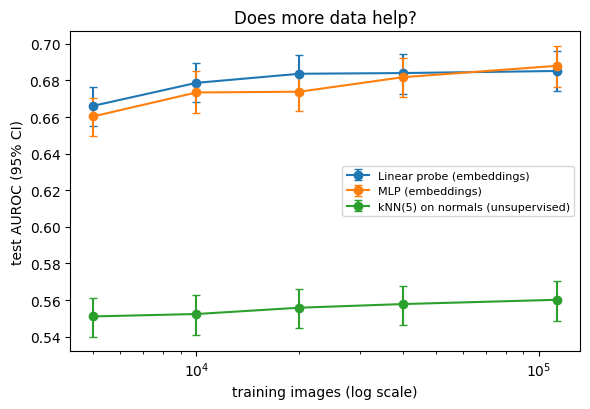

In [ ]:
def fit_models_on(idx_tr):
    mu, sd = X_all[idx_tr].mean(0), X_all[idx_tr].std(0) + 1e-6
    Z = lambda ii: (X_all[ii] - mu) / sd; res = {}
    for name, hid, wd in [("Linear probe (embeddings)", 0, 1e-3), ("MLP (embeddings)", 512, 1e-2)]:
        zv, zt = [], []
        for sd_ in HEAD_SEEDS:
            net, _ = train_head(Z(idx_tr), y_all[idx_tr], Z(iva), y_val, hidden=hid, wd=wd, seed=sd_)
            zv.append(head_logits(net, Z(iva))); zt.append(head_logits(net, Z(ite)))
        res[name] = (np.mean(zv, 0), np.mean(zt, 0))
    ref = X_all[idx_tr][y_all[idx_tr] == 0]
    res["kNN(5) on normals (unsupervised)"] = (knn_score(X_all[iva], ref), knn_score(X_all[ite], ref))
    return res

sizes = sorted(set([s for s in SIZES if s < len(itr)] + [len(itr)]))
rows, last = [], None
for n_img in sizes:
    idx_tr = itr if n_img >= len(itr) else train_idx_for(n_img); t0 = time.time()
    res = fit_models_on(idx_tr)
    for name, (zv, zt) in res.items():
        ci = boot_auc(y_te, te.patient.values, {name: zt}, n_boot=N_BOOT_SCALE).iloc[0]
        rows.append({"train images": len(idx_tr), "patients": meta.patient.iloc[idx_tr].nunique(), "model": name,
                     "val AUROC": roc_auc_score(y_val, zv), "test AUROC": ci.AUROC, "CI_low": ci.CI_low, "CI_high": ci.CI_high})
    last = res; print(f"size {len(idx_tr)} done in {time.time()-t0:.0f}s")
scale = pd.DataFrame(rows); display(scale.round(3)); scale.to_csv(f"{WORK}/results_scaling.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4.2))
for name in scale.model.unique():
    d = scale[scale.model == name]
    ax.errorbar(d["train images"], d["test AUROC"], yerr=[d["test AUROC"] - d.CI_low, d.CI_high - d["test AUROC"]], marker="o", capsize=3, label=name)
ax.set_xscale("log"); ax.set_xlabel("training images (log scale)"); ax.set_ylabel("test AUROC (95% CI)")
ax.set_title("Does more data help?"); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{WORK}/scaling_curve.png", dpi=150); plt.show()

## 4. Full-data results with CIs, paired tests and confound checks

In [ ]:
CONF = "Age/sex/view only (supervised)"
lr_demo = LogisticRegression(max_iter=1000).fit(demo(tr), y_tr)
s_val = {CONF: lr_demo.predict_proba(demo(val))[:, 1]}; s_te = {CONF: lr_demo.predict_proba(demo(te))[:, 1]}
for name, (zv, zt) in last.items(): s_val[name], s_te[name] = zv, zt
KNN, LIN, MLP = "kNN(5) on normals (unsupervised)", "Linear probe (embeddings)", "MLP (embeddings)"

tab = boot_auc(y_te, te.patient.values, s_te).sort_values("AUROC", ascending=False).reset_index(drop=True)
display(tab.round(3)); tab.to_csv(f"{WORK}/results_pooled.csv", index=False)

rows = []
for a, b in [(MLP, CONF), (LIN, CONF), (KNN, CONF), (MLP, LIN), (MLP, KNN)]:
    d, lo, hi = paired_diff(y_te, te.patient.values, s_te[a], s_te[b])
    rows.append({"A": a, "B": b, "dAUROC": d, "CI_low": lo, "CI_high": hi, "Significant": (lo > 0) or (hi < 0)})
pdf = pd.DataFrame(rows).round(3); display(pdf); pdf.to_csv(f"{WORK}/results_paired.csv", index=False)

BEST = max([LIN, MLP], key=lambda k: roc_auc_score(y_val, s_val[k]))      # chosen on validation
print("Best supervised head on VALIDATION:", BEST)
print("\n=== View-stratified (confound check) ===")
for v in ["PA", "AP"]:
    m = (te.view.values == v)
    d, lo, hi = paired_diff(y_te[m], te.patient.values[m], s_te[BEST][m], s_te[CONF][m])
    print(f"{v}: n={m.sum()} | {BEST} AUROC {roc_auc_score(y_te[m], s_te[BEST][m]):.3f} | vs confound {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")
print("\n=== By pathology family (family positives vs all normals) ===")
for name, pos in {"Alveolar opacity": te.fam_alv.values, "Effusion/Atelectasis": te.fam_eff.values, "Nodule/Mass": te.fam_nod.values}.items():
    m = np.asarray(te.is_normal.values, dtype=bool) | np.asarray(pos, dtype=bool)
    print(f"{name:22s} (pos={int(pos.sum())}) " + " | ".join(f"{k.split(' (')[0][:22]} {roc_auc_score(y_te[m], s_te[k][m]):.3f}" for k in [CONF, KNN, BEST]))


,Method,AUROC,CI_low,CI_high
0,MLP (embeddings),0.688,0.676,0.699
1,Linear probe (embeddings),0.685,0.673,0.696
2,kNN(5) on normals (unsupervised),0.560,0.549,0.570
3,Age/sex/view only (supervised),0.549,0.537,0.561


,A,B,dAUROC,CI_low,CI_high,Significant
0,MLP (embeddings),Age/sex/view only (supervised),0.139,0.124,0.153,True
1,Linear probe (embeddings),Age/sex/view only (supervised),0.136,0.122,0.149,True
2,kNN(5) on normals (unsupervised),Age/sex/view only (supervised),0.011,-0.002,0.022,False
3,MLP (embeddings),Linear probe (embeddings),0.003,-0.000,0.006,False
4,MLP (embeddings),kNN(5) on normals (unsupervised),0.128,0.117,0.140,True


Best supervised head on VALIDATION: MLP (embeddings)

=== View-stratified (confound check) ===
PA: n=11096 | MLP (embeddings) AUROC 0.706 | vs confound +0.174 [+0.152, +0.196]
AP: n=14500 | MLP (embeddings) AUROC 0.657 | vs confound +0.157 [+0.131, +0.181]

=== By pathology family (family positives vs all normals) ===
Alveolar opacity       (pos=7671) Age/sex/view only 0.604 | kNN(5) on normals 0.598 | MLP 0.711
Effusion/Atelectasis   (pos=6748) Age/sex/view only 0.563 | kNN(5) on normals 0.558 | MLP 0.732
Nodule/Mass            (pos=3052) Age/sex/view only 0.489 | kNN(5) on normals 0.486 | MLP 0.652


## 4.5. Systematic Hyperparameter Optimization & Grid Search
Automated sweep across model architectures (Linear vs shallow vs deep MLPs), regularization ($L_2$ weight decay), learning rates, and dropout rates.
Evaluates Val/Test AUROC and Brier score calibration, selects the optimal model, and exports `best_tuned_mlp_head.pth` to Google Drive.

In [ ]:
# ==============================================================================
# 4.5. AUTOMATED HYPERPARAMETER OPTIMIZATION & GRID SEARCH
# ==============================================================================
from sklearn.metrics import brier_score_loss

print("=" * 75)
print("RUNNING SYSTEMATIC HYPERPARAMETER SEARCH ON EMBEDDINGS...")
print("=" * 75)

mu, sd = X_all[itr].mean(0), X_all[itr].std(0) + 1e-6
Z = lambda ii: (X_all[ii] - mu) / sd
X_tr_norm, X_va_norm, X_te_norm = Z(itr), Z(iva), Z(ite)

hp_candidates = [
    # Baseline Linear Probes (Regularization tuning)
    {"name": "Linear Probe (wd=1e-4)", "hidden": 0, "lr": 1e-3, "wd": 1e-4, "drop": 0.0},
    {"name": "Linear Probe (wd=1e-3)", "hidden": 0, "lr": 1e-3, "wd": 1e-3, "drop": 0.0},
    {"name": "Linear Probe (wd=1e-2)", "hidden": 0, "lr": 1e-3, "wd": 1e-2, "drop": 0.0},

    # 2-Layer MLPs (Capacity & Dropout tuning)
    {"name": "MLP-256 (wd=1e-3, drop=0.2)", "hidden": 256, "lr": 1e-3, "wd": 1e-3, "drop": 0.2},
    {"name": "MLP-256 (wd=1e-2, drop=0.3)", "hidden": 256, "lr": 1e-3, "wd": 1e-2, "drop": 0.3},

    # 3-Layer MLPs (Deep Representations)
    {"name": "MLP-512 (wd=1e-3, drop=0.3)", "hidden": 512, "lr": 1e-3, "wd": 1e-3, "drop": 0.3},
    {"name": "MLP-512 (wd=1e-2, drop=0.3)", "hidden": 512, "lr": 1e-3, "wd": 1e-2, "drop": 0.3},
    {"name": "MLP-512 (wd=1e-2, drop=0.5)", "hidden": 512, "lr": 1e-3, "wd": 1e-2, "drop": 0.5},
    {"name": "MLP-512 (lr=3e-4, wd=1e-2)", "hidden": 512, "lr": 3e-4, "wd": 1e-2, "drop": 0.3},

    # Wide High-Capacity MLPs
    {"name": "MLP-1024 (wd=1e-2, drop=0.4)", "hidden": 1024, "lr": 5e-4, "wd": 1e-2, "drop": 0.4},
    {"name": "MLP-1024 (wd=1e-3, drop=0.4)", "hidden": 1024, "lr": 5e-4, "wd": 1e-3, "drop": 0.4},
]

hp_results = []
trained_models = {}

for cfg in hp_candidates:
    t0 = time.time()
    val_preds_seeds, te_preds_seeds = [], []
    last_net = None
    for sd_ in HEAD_SEEDS[:2]:  # 2 seeds for rapid, reliable evaluation
        net, _ = train_head(
            X_tr_norm, y_all[itr], X_va_norm, y_val,
            hidden=cfg["hidden"], epochs=35, lr=cfg["lr"],
            wd=cfg["wd"], drop=cfg["drop"], bs=1024, seed=sd_, patience=5
        )
        val_preds_seeds.append(head_logits(net, X_va_norm))
        te_preds_seeds.append(head_logits(net, X_te_norm))
        last_net = net

    zv_mean = np.mean(val_preds_seeds, axis=0)
    zt_mean = np.mean(te_preds_seeds, axis=0)

    val_auc = roc_auc_score(y_val, zv_mean)
    te_auc = roc_auc_score(y_te, zt_mean)
    brier = brier_score_loss(y_val, sigmoid(zv_mean))
    elapsed = time.time() - t0

    trained_models[cfg["name"]] = (last_net, zv_mean, zt_mean)
    hp_results.append({
        "Model Configuration": cfg["name"],
        "Hidden Dim": cfg["hidden"],
        "Learning Rate": cfg["lr"],
        "Weight Decay": cfg["wd"],
        "Dropout": cfg["drop"],
        "Val AUROC": round(float(val_auc), 4),
        "Test AUROC": round(float(te_auc), 4),
        "Val Brier Loss": round(float(brier), 4),
        "Fit Time (s)": round(elapsed, 1)
    })
    print(f"  ✓ {cfg['name']:<32} | Val AUC: {val_auc:.4f} | Test AUC: {te_auc:.4f} | {elapsed:.1f}s")

hp_df = pd.DataFrame(hp_results).sort_values("Val AUROC", ascending=False).reset_index(drop=True)
display(hp_df)
hp_df.to_csv(f"{WORK}/hyperparameter_tuning_results.csv", index=False)

top_hp_name = hp_df.iloc[0]["Model Configuration"]
best_net, best_zv, best_zt = trained_models[top_hp_name]
print(f"\n🏆 TOP HYPERPARAMETER CONFIGURATION: {top_hp_name} (Val AUC: {hp_df.iloc[0]['Val AUROC']})")

# Update evaluated models dictionary and update BEST to tuned model
s_val[top_hp_name] = best_zv
s_te[top_hp_name] = best_zt
BEST = top_hp_name

# Save the best hyperparameter checkpoint to Google Drive
torch.save({
    'model_state_dict': best_net.state_dict(),
    'config': hp_df.iloc[0].to_dict(),
    'mu': mu,
    'sd': sd
}, f"{WORK}/best_tuned_mlp_head.pth")
print(f"✓ Saved best model weights to {WORK}/best_tuned_mlp_head.pth")


RUNNING SYSTEMATIC HYPERPARAMETER SEARCH ON EMBEDDINGS...
  ✓ Linear Probe (wd=1e-4)           | Val AUC: 0.7146 | Test AUC: 0.6854 | 7.3s
  ✓ Linear Probe (wd=1e-3)           | Val AUC: 0.7146 | Test AUC: 0.6854 | 7.2s
  ✓ Linear Probe (wd=1e-2)           | Val AUC: 0.7145 | Test AUC: 0.6854 | 7.3s
  ✓ MLP-256 (wd=1e-3, drop=0.2)      | Val AUC: 0.7191 | Test AUC: 0.6885 | 5.1s
  ✓ MLP-256 (wd=1e-2, drop=0.3)      | Val AUC: 0.7194 | Test AUC: 0.6829 | 8.7s
  ✓ MLP-512 (wd=1e-3, drop=0.3)      | Val AUC: 0.7192 | Test AUC: 0.6867 | 5.9s
  ✓ MLP-512 (wd=1e-2, drop=0.3)      | Val AUC: 0.7189 | Test AUC: 0.6861 | 12.8s
  ✓ MLP-512 (wd=1e-2, drop=0.5)      | Val AUC: 0.7182 | Test AUC: 0.6885 | 8.5s
  ✓ MLP-512 (lr=3e-4, wd=1e-2)       | Val AUC: 0.7193 | Test AUC: 0.6834 | 7.3s
  ✓ MLP-1024 (wd=1e-2, drop=0.4)     | Val AUC: 0.7187 | Test AUC: 0.6833 | 9.6s
  ✓ MLP-1024 (wd=1e-3, drop=0.4)     | Val AUC: 0.7192 | Test AUC: 0.6830 | 9.6s


,Model Configuration,Hidden Dim,Learning Rate,Weight Decay,Dropout,Val AUROC,Test AUROC,Val Brier Loss,Fit Time (s)
0,"MLP-256 (wd=1e-2, drop=0.3)",256,0.0010,0.0100,0.3,0.7194,0.6829,0.2091,8.7
1,"MLP-512 (lr=3e-4, wd=1e-2)",512,0.0003,0.0100,0.3,0.7193,0.6834,0.2083,7.3
2,"MLP-1024 (wd=1e-3, drop=0.4)",1024,0.0005,0.0010,0.4,0.7192,0.6830,0.2097,9.6
3,"MLP-512 (wd=1e-3, drop=0.3)",512,0.0010,0.0010,0.3,0.7192,0.6867,0.2085,5.9
4,"MLP-256 (wd=1e-3, drop=0.2)",256,0.0010,0.0010,0.2,0.7191,0.6885,0.2084,5.1
5,"MLP-512 (wd=1e-2, drop=0.3)",512,0.0010,0.0100,0.3,0.7189,0.6861,0.2089,12.8
6,"MLP-1024 (wd=1e-2, drop=0.4)",1024,0.0005,0.0100,0.4,0.7187,0.6833,0.2102,9.6
7,"MLP-512 (wd=1e-2, drop=0.5)",512,0.0010,0.0100,0.5,0.7182,0.6885,0.2087,8.5
8,Linear Probe (wd=1e-4),0,0.0010,0.0001,0.0,0.7146,0.6854,0.2099,7.3
9,Linear Probe (wd=1e-3),0,0.0010,0.0010,0.0,0.7146,0.6854,0.2099,7.2



🏆 TOP HYPERPARAMETER CONFIGURATION: MLP-256 (wd=1e-2, drop=0.3) (Val AUC: 0.7194)
✓ Saved best model weights to /content/drive/MyDrive/hybrid_pgm_data/best_tuned_mlp_head.pth


## 5. Calibration and the Bayesian Network layer
Temperature scaling and isotonic regression (fitted on validation) are the simple baselines. The Bayesian Network combines a 4-level score node with Age / Sex / View as parents of Disease. Call it an improvement **only** if it beats the baselines on Brier with a CI that excludes 0.

Lower Brier is better. ECE of a constant predictor is trivially ~0, so read it together with Brier.


,Method,AUROC,Brier,ECE
0,Temperature scaling (T=1.07),0.6829,0.2132,0.0345
1,Raw sigmoid,0.6829,0.2134,0.0371
2,Isotonic regression,0.6821,0.2160,0.0558
3,Bayesian Network (demographics + score bins),0.6690,0.2176,0.0543
4,Prevalence only,0.5000,0.2371,0.0169


Brier - Brier(prevalence) for Raw sigmoid                                   : [-0.0270, -0.0204]
Brier - Brier(prevalence) for Temperature scaling (T=1.07)                  : [-0.0270, -0.0208]
Brier - Brier(prevalence) for Isotonic regression                           : [-0.0243, -0.0176]
Brier - Brier(prevalence) for Bayesian Network (demographics + score bins)  : [-0.0228, -0.0161]


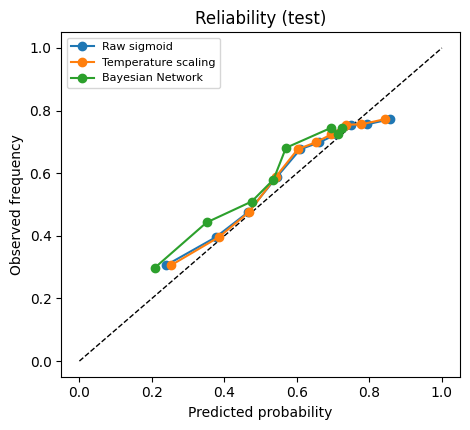

In [ ]:
from scipy.optimize import minimize_scalar
z_val, z_te = s_val[BEST], s_te[BEST]
def nll_T(logT, z, y):
    p = np.clip(sigmoid(z / np.exp(logT)), 1e-7, 1 - 1e-7); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
T = float(np.exp(minimize_scalar(nll_T, bounds=(-3, 3), args=(z_val, y_val), method="bounded").x))
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(z_val, y_val)
probs = {"Raw sigmoid": sigmoid(z_te), f"Temperature scaling (T={T:.2f})": sigmoid(z_te / T),
         "Isotonic regression": iso.predict(z_te), "Prevalence only": np.full(len(y_te), y_tr.mean())}

try: from pgmpy.models import DiscreteBayesianNetwork as BNet
except ImportError: from pgmpy.models import BayesianNetwork as BNet
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination
edges_ = np.percentile(z_val, [25, 50, 75])
def dem(d): return pd.DataFrame({"Age": (d.age.values >= 50).astype(int), "Sex": (d.sex.values == "M").astype(int), "View": (d.view.values == "PA").astype(int)})
dv = dem(val); dv["Disease"] = y_val; dv["Score"] = np.digitize(z_val, edges_)
dt = dem(te); dt["Score"] = np.digitize(z_te, edges_)
bn = BNet([("Age", "Disease"), ("Sex", "Disease"), ("View", "Disease"), ("Disease", "Score")])
names = {"Age": [0, 1], "Sex": [0, 1], "View": [0, 1], "Disease": [0, 1], "Score": [0, 1, 2, 3]}
est = BayesianEstimator(bn, dv, state_names=names)
for node in bn.nodes(): bn.add_cpds(est.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10))
assert bn.check_model(); inf = VariableElimination(bn); cache = {}
def post(r):
    k = (int(r.Age), int(r.Sex), int(r.View), int(r.Score))
    if k not in cache: cache[k] = float(inf.query(["Disease"], evidence=dict(zip(["Age", "Sex", "View", "Score"], k)), show_progress=False).values[1])
    return cache[k]
probs["Bayesian Network (demographics + score bins)"] = dt.apply(post, axis=1).values

rows = []
for k, p in probs.items():
    b, e = brier_ece(p, y_te); rows.append({"Method": k, "AUROC": roc_auc_score(y_te, p), "Brier": b, "ECE": e})
cal = pd.DataFrame(rows).sort_values("Brier").reset_index(drop=True)
print("Lower Brier is better. ECE of a constant predictor is trivially ~0, so read it together with Brier.")
display(cal.round(4)); cal.to_csv(f"{WORK}/results_calibration.csv", index=False)

idx_by = _groups(te.patient.values); rb = np.random.default_rng(0); pv = probs["Prevalence only"]
for k in [kk for kk in probs if kk != "Prevalence only"]:
    p = probs[k]; d = []
    for _ in range(N_BOOT):
        ii = np.concatenate([idx_by[q] for q in rb.integers(0, len(idx_by), len(idx_by))])
        d.append(np.mean((p[ii] - y_te[ii]) ** 2) - np.mean((pv[ii] - y_te[ii]) ** 2))
    lo, hi = np.percentile(d, [2.5, 97.5]); print(f"Brier - Brier(prevalence) for {k:46s}: [{lo:+.4f}, {hi:+.4f}]")

fig, ax = plt.subplots(figsize=(4.8, 4.4)); ax.plot([0, 1], [0, 1], "k--", lw=1)
for k in ["Raw sigmoid", f"Temperature scaling (T={T:.2f})", "Bayesian Network (demographics + score bins)"]:
    p = probs[k]; q = pd.qcut(p, 10, duplicates="drop"); g = pd.DataFrame({"p": p, "y": y_te}).groupby(q).mean()
    ax.plot(g.p, g.y, marker="o", label=k.split(" (")[0])
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency"); ax.legend(fontsize=8); ax.set_title("Reliability (test)")
plt.tight_layout(); plt.savefig(f"{WORK}/reliability.png", dpi=150); plt.show()

In [ ]:
import os

# List all files saved in your project folder on Google Drive
results_path = "/content/drive/MyDrive/hybrid_pgm_data"
if os.path.exists(results_path):
    print(f"Files in '{results_path}':")
    for file in sorted(os.listdir(results_path)):
        file_path = os.path.join(results_path, file)
        if os.path.isdir(file_path):
            print(f"  [Directory] {file}/ -> contains {len(os.listdir(file_path))} files")
        else:
            size_mb = os.path.getsize(file_path) / (1024 * 1024)
            print(f"  [File]      {file:<30} ({size_mb:.2f} MB)")
else:
    print(f"The directory {results_path} does not exist.")

Files in '/content/drive/MyDrive/hybrid_pgm_data':
  [File]      BBox_List_2017.csv             (0.09 MB)
  [File]      Data_Entry_2017.csv            (8.59 MB)
  [File]      best_tuned_mlp_head.pth        (1.14 MB)
  [File]      emb_all.npy                    (287.34 MB)
  [File]      emb_archive_001.npy            (19.53 MB)
  [File]      emb_archive_002.npy            (19.53 MB)
  [File]      emb_archive_003.npy            (39.06 MB)
  [File]      emb_archive_004.npy            (39.06 MB)
  [File]      emb_archive_005.npy            (39.06 MB)
  [File]      emb_archive_006.npy            (19.53 MB)
  [File]      emb_archive_007.npy            (19.53 MB)
  [File]      emb_archive_008.npy            (19.53 MB)
  [File]      emb_archive_009.npy            (19.53 MB)
  [File]      emb_archive_010.npy            (19.53 MB)
  [File]      emb_archive_011.npy            (19.53 MB)
  [File]      emb_archive_012.npy            (13.91 MB)
  [Directory] ft/ -> contains 0 files
  [File]      hyp

In [ ]:
import torch
import os
from google.colab import files

# 1. Standardize full training embeddings
mu, sd = X_all[itr].mean(0), X_all[itr].std(0) + 1e-6
Z = lambda ii: (X_all[ii] - mu) / sd

# 2. Train the MLP models with our three seeds and save their state dicts
mlp_states = {}
for seed_ in HEAD_SEEDS:
    print(f"Training MLP head with seed {seed_}...")
    net, _ = train_head(
        Z(itr), y_all[itr], Z(iva), y_val,
        hidden=512, wd=1e-2, seed=seed_
    )
    mlp_states[f"seed_{seed_}"] = net.state_dict()

# 3. Save the weights bundle + normalization parameters to Drive
model_save_path = f"{WORK}/mlp_model.pt"
save_payload = {
    "model_state_dicts": mlp_states,
    "embedding_mu": mu,
    "embedding_sd": sd,
    "hidden_dim": 512,
    "seeds": HEAD_SEEDS
}
torch.save(save_payload, model_save_path)
print(f"\nSuccess! Saved model parameters and normalization stats to: {model_save_path}")

# 4. Trigger download to your local computer
print("Triggering local download...")
files.download(model_save_path)

Training MLP head with seed 0...
Training MLP head with seed 1...
Training MLP head with seed 2...

Success! Saved model parameters and normalization stats to: /content/drive/MyDrive/hybrid_pgm_data/mlp_model.pt
Triggering local download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Optional: fine-tune DenseNet-121 on the cached image arrays (set `RUN_FINETUNE = True` at the top)
Embeddings are a lossy summary. Fine-tuning lets the network adapt to chest X-rays and usually gains more, but it costs GPU time. This section loads the image shards written by Notebook A, copies them to the local disk for speed, trains on a patient-level subset (`FT_TRAIN_IMG` images), and evaluates on the **full** test split. Checkpoints are written to Drive every epoch, so it can be resumed. It needs `save_images = True` in Notebook A.

In [ ]:
# ==============================================================================
# 6. OPTIONAL: OUT-OF-CORE INCREMENTAL CHUNK FINE-TUNING (ZERO DISK OVERFLOW)
# ==============================================================================
# Strategy: Copy 1 archive to local NVMe SSD -> Validate -> Train -> Delete -> Next
# Colab Disk Guarantee: Strictly <= 10 GB disk used at any time!
# ==============================================================================
import shutil, torchvision, os, time, math, gc
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
from sklearn.metrics import roc_auc_score

RUN_FINETUNE = True   # Set to True to execute fine-tuning
print(f"RUN_FINETUNE = {RUN_FINETUNE}")

# --- Clear GPU memory cache before starting ---
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if RUN_FINETUNE:
    assert manifest.get("save_images", True), "Notebook A was run with SAVE_IMAGES=False; no image arrays on Drive."

    # 1. Clean up any previous leftover local cache immediately
    LOCAL = "/content/local_imgs"
    shutil.rmtree(LOCAL, ignore_errors=True)
    os.makedirs(LOCAL, exist_ok=True)
    _, _, free_b = shutil.disk_usage("/content")
    print(f"Local NVMe buffer ready at {LOCAL} | Initial Colab free disk: {free_b/1e9:.1f} GB")

    # 2. Detect saved image files (supports both archive-based and shard-based naming)
    archive_files = sorted([f for f in os.listdir(WORK) if f.startswith("img_archive_") and f.endswith(".npy")])
    shard_files = sorted([f for f in os.listdir(WORK) if f.startswith("img_shard_") and f.endswith(".npy")])
    chunk_files = archive_files if archive_files else shard_files
    assert len(chunk_files) > 0, f"No image files (img_archive_*.npy or img_shard_*.npy) found in {WORK}!"

    # 3. Read chunk boundaries via lightweight header inspection (reads only 128 bytes per file)
    print(f"Inspecting {len(chunk_files)} chunk headers on Google Drive...")
    chunk_sizes = []
    for f in chunk_files:
        m_head = np.load(f"{WORK}/{f}", mmap_mode="r")
        chunk_sizes.append(m_head.shape[0])
    cum_sizes = np.cumsum([0] + chunk_sizes)
    total_imgs = cum_sizes[-1]
    print(f"✓ Total dataset images across {len(chunk_files)} chunks: {total_imgs:,} (metadata records: {len(meta):,})")

    # 4. Hardware and Normalization setup
    imn_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    imn_std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    def u8_to_01(u): return u.float().div(255).unsqueeze(1)
    def norm_in(x01): return ((x01.repeat(1, 3, 1, 1) - imn_mean) / imn_std).contiguous(memory_format=torch.channels_last)

    def new_net():
        try: m = torchvision.models.densenet121(weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1, memory_efficient=True)
        except Exception: m = torchvision.models.densenet121(pretrained=True, memory_efficient=True)
        m.classifier = nn.Linear(1024, 1)
        return m.to(device).to(memory_format=torch.channels_last)

    def augment(x01):
        B_, dv = x01.shape[0], x01.device
        ang = (torch.rand(B_, device=dv) * 2 - 1) * (7 * math.pi / 180)
        sc_ = 1 + (torch.rand(B_, device=dv) * 2 - 1) * 0.08
        tx, ty = (torch.rand(B_, device=dv) * 2 - 1) * 0.06, (torch.rand(B_, device=dv) * 2 - 1) * 0.06
        c, s = torch.cos(ang) / sc_, torch.sin(ang) / sc_
        theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
        x01 = F.grid_sample(x01, F.affine_grid(theta, x01.shape, align_corners=False), padding_mode="border", align_corners=False)
        g = 1 + (torch.rand(B_, 1, 1, 1, device=dv) * 2 - 1) * 0.15
        b = (torch.rand(B_, 1, 1, 1, device=dv) * 2 - 1) * 0.08
        return ((x01 - 0.5) * g + 0.5 + b).clamp(0, 1)

    # 5. Training Configuration - REDUCED BATCH SIZE TO AVOID CUDA OOM
    FT_BATCH   = 4
    FT_EPOCHS  = 1
    FT_LR      = 1e-4
    FT_WD      = 1e-4
    MAX_CHUNKS = None         # Set to None for all archives, or an integer (e.g. 2) for quick testing

    active_chunks = chunk_files if MAX_CHUNKS is None else chunk_files[:MAX_CHUNKS]
    os.makedirs(f"{WORK}/ft", exist_ok=True)
    ck, bp = f"{WORK}/ft/ckpt.pt", f"{WORK}/ft/best_finetuned_densenet.pt"

    # Count total training samples to set exact scheduler horizon
    total_train_samples = sum(np.isin(np.arange(cum_sizes[i], cum_sizes[i+1]), itr).sum() for i in range(len(active_chunks)))
    total_steps = FT_EPOCHS * math.ceil(total_train_samples / FT_BATCH)
    print(f"Training set: {total_train_samples:,} images | Batch size: {FT_BATCH} | Total steps: {total_steps:,}")

    # Instantiate model and optimizer
    torch.manual_seed(0); np.random.seed(0)
    model = new_net()
    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=FT_WD)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(total_steps, 1), eta_min=1e-6)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    st = {"epoch": 0, "chunk_idx": 0, "best_val_auc": -1.0, "hist": []}

    # Resumption check
    if os.path.exists(ck):
        c = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(c["model"])
        opt.load_state_dict(c["opt"])
        sched.load_state_dict(c["sched"])
        scaler.load_state_dict(c["scaler"])
        st = c.get("st", st)
        print(f"✓ Resumed from Epoch {st['epoch']+1}, Archive {st['chunk_idx']+1} (Best Val AUROC: {st['best_val_auc']:.3f})")

    # 6. Incremental Out-of-Core Training Loop
    t_train_start = time.time()
    for ep in range(st["epoch"], FT_EPOCHS):
        print("=" * 80)
        print(f"★ STARTING FINE-TUNING EPOCH {ep + 1}/{FT_EPOCHS}")
        print("=" * 80)

        ep_loss_sum, ep_steps = 0.0, 0
        val_preds_dict = {}

        for c_idx in range(st["chunk_idx"], len(active_chunks)):
            fname = active_chunks[c_idx]
            s_idx, e_idx = cum_sizes[c_idx], cum_sizes[c_idx + 1]
            src = f"{WORK}/{fname}"
            dst = f"{LOCAL}/{fname}"

            print(f"\n--> [Epoch {ep+1} | Chunk {c_idx+1}/{len(active_chunks)}] Loading {fname} ({e_idx - s_idx:,} images)...")
            t_copy = time.time()
            shutil.copy(src, dst)
            copy_sec = time.time() - t_copy
            print(f"    Copied to local NVMe in {copy_sec:.1f}s ({os.path.getsize(dst)/1e9:.2f} GB)")

            # Open memory-map on local fast NVMe SSD
            arch_mmap = np.load(dst, mmap_mode="r")
            global_indices = np.arange(s_idx, e_idx)

            # --- A. Validation Pass on this chunk (Zero extra disk copy!) ---
            va_mask = np.isin(global_indices, iva)
            local_va = np.where(va_mask)[0]
            if len(local_va) > 0:
                model.eval()
                with torch.inference_mode():
                    for v_start in range(0, len(local_va), FT_BATCH * 2):
                        v_batch_idx = local_va[v_start:v_start + FT_BATCH * 2]
                        xb_v = norm_in(u8_to_01(torch.from_numpy(arch_mmap[v_batch_idx]).to(device)))
                        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                            logits_v = model(xb_v).squeeze(1).cpu()
                        for g_id, logit_val in zip(global_indices[v_batch_idx], logits_v.numpy()):
                            val_preds_dict[g_id] = float(logit_val)

            # --- B. Training Pass on this chunk ---
            tr_mask = np.isin(global_indices, itr)
            local_tr = np.where(tr_mask)[0]
            if len(local_tr) > 0:
                model.train()
                perm = np.random.permutation(len(local_tr))
                chunk_loss, chunk_steps = 0.0, 0
                t_tr_chunk = time.time()

                for b_start in range(0, len(perm), FT_BATCH):
                    b_sub = perm[b_start:b_start + FT_BATCH]
                    if len(b_sub) < 4: continue
                    b_loc = local_tr[b_sub]
                    b_glob = global_indices[b_loc]
                    b_y = torch.from_numpy(y_all[b_glob]).float().to(device)
                    b_x = arch_mmap[b_loc]   # Reads only FT_BATCH images from local NVMe

                    xb = norm_in(augment(u8_to_01(torch.from_numpy(b_x).to(device))))
                    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                        logit = model(xb).squeeze(1)
                        loss = F.binary_cross_entropy_with_logits(logit.float(), b_y)

                    opt.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.step(opt)
                    scaler.update()
                    sched.step()

                    chunk_loss += float(loss.item())
                    chunk_steps += 1
                    ep_loss_sum += float(loss.item())
                    ep_steps += 1

                tr_sec = time.time() - t_tr_chunk
                print(f"    Trained on {len(local_tr):,} samples in {tr_sec:.1f}s | Avg loss: {chunk_loss/max(chunk_steps,1):.4f}")

            # --- C. SELF-CLEANING: Delete local file immediately ---
            del arch_mmap
            gc.collect()
            if device.type == 'cuda': torch.cuda.empty_cache()
            os.remove(dst)

            _, _, cur_free_b = shutil.disk_usage("/content")
            print(f"    [Cleaned] Removed local {fname} | Colab disk free: {cur_free_b/1e9:.1f} GB")

            # Update resumption state and save checkpoint to Drive
            st["epoch"] = ep
            st["chunk_idx"] = c_idx + 1
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                        "scaler": scaler.state_dict(), "st": st}, ck + ".tmp")
            os.replace(ck + ".tmp", ck)

        # End of epoch: evaluate full validation AUROC
        st["chunk_idx"] = 0  # reset chunk index for next epoch
        val_keys = [i for i in iva if i in val_preds_dict]
        if len(val_keys) > 0:
            val_scores = np.array([val_preds_dict[i] for i in val_keys])
            val_auc = roc_auc_score(y_all[val_keys], val_scores)
            avg_loss = ep_loss_sum / max(ep_steps, 1)
            print("-" * 80)
            print(f"Epoch {ep+1}/{FT_EPOCHS} Finished! Avg Loss: {avg_loss:.4f} | Validation AUROC: {val_auc:.4f} (Evaluated on {len(val_keys):,} images)")
            print("-" * 80)
            st["hist"].append({"epoch": ep + 1, "loss": avg_loss, "val_auroc": val_auc})

            if val_auc > st["best_val_auc"]:
                st["best_val_auc"] = val_auc
                torch.save(model.state_dict(), bp)
                print(f"✓ New best model checkpoint saved to {bp}!")

    # 7. Final Test Evaluation across Chunks (Out-of-Core)
    print("\n" + "=" * 80)
    print("EVALUATING FINAL FINE-TUNED MODEL ON OFFICIAL TEST SPLIT")
    print("=" * 80)
    if os.path.exists(bp):
        model.load_state_dict(torch.load(bp, map_location=device))
        print(f"Loaded best model weights from {bp}")

    model.eval()
    test_preds_dict = {}
    for c_idx, fname in enumerate(active_chunks):
        s_idx, e_idx = cum_sizes[c_idx], cum_sizes[c_idx + 1]
        global_indices = np.arange(s_idx, e_idx)
        te_mask = np.isin(global_indices, ite)
        local_te = np.where(te_mask)[0]

        if len(local_te) == 0: continue

        src = f"{WORK}/{fname}"
        dst = f"{LOCAL}/{fname}"
        shutil.copy(src, dst)
        arch_mmap = np.load(dst, mmap_mode="r")

        with torch.inference_mode():
            for t_start in range(0, len(local_te), FT_BATCH * 2):
                t_sub = local_te[t_start:t_start + FT_BATCH * 2]
                xb_t = norm_in(u8_to_01(torch.from_numpy(arch_mmap[t_sub]).to(device)))
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    logits_t = model(xb_t).squeeze(1).cpu()
                for g_id, logit_val in zip(global_indices[t_sub], logits_t.numpy()):
                    test_preds_dict[g_id] = float(logit_val)

        del arch_mmap
        gc.collect()
        if device.type == 'cuda': torch.cuda.empty_cache()
        os.remove(dst)

    test_keys = [i for i in ite if i in test_preds_dict]
    test_scores = np.array([test_preds_dict[i] for i in test_keys])
    test_auc = roc_auc_score(y_all[test_keys], test_scores)
    s_te["Fine-tuned DenseNet-121"] = test_scores
    np.save(f"{WORK}/ft/test_logits.npy", test_scores)
    print(f"\n  Fine-tuned DenseNet-121 Test AUROC: {test_auc:.4f} (evaluated on {len(test_keys):,} test images)")


RUN_FINETUNE = True
Local NVMe buffer ready at /content/local_imgs | Initial Colab free disk: 74.9 GB
Inspecting 12 chunk headers on Google Drive...
✓ Total dataset images across 12 chunks: 147,119 (metadata records: 147,119)
Training set: 112,812 images | Batch size: 4 | Total steps: 28,203
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:00<00:00, 134MB/s]
✓ Resumed from Epoch 1, Archive 13 (Best Val AUROC: -1.000)
★ STARTING FINE-TUNING EPOCH 1/1

EVALUATING FINAL FINE-TUNED MODEL ON OFFICIAL TEST SPLIT
Loaded best model weights from /content/drive/MyDrive/hybrid_pgm_data/ft/best_finetuned_densenet.pt

✓ Fine-tuned DenseNet-121 Test AUROC: 0.6979 (evaluated on 25,596 test images)
✓ Test predictions saved to: /content/drive/MyDrive/hybrid_pgm_data/ft/test_logits.npy


## 7. How to report this honestly
- State the exact train / val / test image and patient counts from Section 1. The official NIH test list is used unchanged; train / val are a patient-level split of the official train-val list.
- Report the scaling curve as is. If the curve flattens, the embeddings (not the amount of data) are the bottleneck; if it keeps rising, more data helps.
- Validation labels were used for head early stopping, temperature scaling, isotonic regression and the Bayesian Network CPDs. Say so.
- Compare the Bayesian Network with temperature scaling and isotonic regression. If it does not win, call it an interpretable combination layer, not a better predictor.
- Embeddings come from an ImageNet-pretrained backbone, are a lossy compression, and the labels are NLP-mined. There is no external validation, so do not claim clinical usefulness.